# 03 · Pre-processing and feature engineering

**Goal:** Turn the raw signals into inputs a model can learn from:
- **physics features** (current magnitude, current², power);
- **EWMA "thermal memory" features**, averages of the recent past, because Phase 2 showed the winding follows the current with a delay of minutes.

**Inputs:**
- `data/processed/measures_v2.parquet` (notebook 01)
- `outputs/results/split_profiles.json` (frozen in notebook 02; loaded, **never re-drawn**)
- `src/config.py`, `src/features.py`

**Outputs:**
- `data/processed/features.parquet`: all rows, 45 model inputs + target + session ID (git-ignored)
- `outputs/results/feature_list.json` (committed) + a copy in `data/processed/`
- `outputs/results/features_summary.json`, `feature_target_correlations.csv`
- Figures `feat_01_ewma_example.png`, `feat_02_feature_target_correlation.png`

**Phase:** 3. Only **training** sessions are used for any analysis. Features are *computed* for test rows too (see section 5 for why that is safe), but nothing is learned from them.

## 1. Setup

In [1]:
import json
import random
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src import config, features
from src.data import load_split
from src.plotting import COLORS, save_figure, use_style

random.seed(config.SEED)
np.random.seed(config.SEED)
use_style()

## 2. Load the data and the frozen split
We load the split from the file made in Phase 2.0. Every teammate gets exactly the same 6 test sessions.

In [2]:
df = pd.read_parquet(config.PARQUET)
split = load_split()
test_profiles = split["test_profiles"]
train_profiles = split["train_profiles"]
print("Rows:", len(df), "| test sessions:", test_profiles, "| training sessions:", len(train_profiles))

Rows: 1330816 | test sessions: [6, 7, 21, 61, 66, 81] | training sessions: 63


## 3. Cleaning (plan 3.1)
Phases 0 and 2 already showed that the data needs **no cleaning**: 0 missing values, 0 duplicate rows, all temperatures physically plausible, and only 5 odd-but-plausible ambient readings, which we keep. Here we simply **re-check** these facts, so the notebook proves them on its own, and confirm the row order is untouched.

In [3]:
n_missing = int(df.isna().sum().sum())
n_duplicates = int(df.duplicated().sum())
block_starts = df[config.GROUP] != df[config.GROUP].shift()
n_blocks = int(block_starts.sum())

print("Missing values:", n_missing)
print("Duplicate rows:", n_duplicates)
print("Session blocks:", n_blocks, "for", df[config.GROUP].nunique(), "sessions (equal = every session is one unbroken block)")
assert n_missing == 0 and n_duplicates == 0 and n_blocks == df[config.GROUP].nunique()

Missing values: 0
Duplicate rows: 0
Session blocks: 69 for 69 sessions (equal = every session is one unbroken block)


## 4. Physics-informed features (plan 3.3)
Each one has a physical meaning:

| Feature | Formula | Why |
|---|---|---|
| `i_s` | √(i_d² + i_q²) | total current magnitude (A), whatever its d/q split |
| `u_s` | √(u_d² + u_q²) | total voltage magnitude (V) |
| `i_s_sq` | i_s² | proportional to **copper loss I²R**, the main heat source in the winding |
| `p_el` | 1.5 × (u_d·i_d + u_q·i_q) | electrical power (W). The 1.5 comes from the amplitude-invariant Park transform |
| `p_mech` | torque × speed × 2π/60 | mechanical power (W); 2π/60 converts rpm to rad/s |

Why `i_s` and not just `i_q`? In Phase 2, `i_q` had r = 0.076 with the winding, because its sign flips between motoring and braking, while both heat the copper. A magnitude doesn't care about the sign.

In [4]:
start = time.time()
df_phys = features.add_physics_features(df)
print(f"Physics features added in {time.time() - start:.1f} s")
df_phys.loc[df_phys[config.GROUP].isin(train_profiles), features.PHYSICS].describe().T.round(2)

Physics features added in 0.4 s


,count,mean,std,min,25%,50%,75%,max
i_s,1189792.0,108.72,86.14,0.00,16.05,111.01,175.74,361.52
u_s,1189792.0,82.03,52.67,0.00,21.33,103.87,130.75,134.26
i_s_sq,1189792.0,19240.98,22097.81,0.00,257.67,12323.27,30883.89,130693.34
p_el,1189792.0,7722.42,18560.68,-44473.03,-5.26,1642.80,20906.85,52471.64
p_mech,1189792.0,6601.41,18551.84,-55121.49,-26.28,1084.35,19914.44,49618.19


## 5. EWMA "thermal memory" features (plan 3.4)
An **EWMA** (exponentially weighted moving average) is an average of the past in which recent values count more and older values fade away smoothly. Its "span" sets how long the memory is.

$$\mu_t = (1-\alpha)\,\mu_{t-1} + \alpha\,x_t, \qquad \alpha = \frac{2}{\text{span}+1}$$

We use spans of **120, 600, 1800 and 5400 samples**. At 2 Hz that's **1, 5, 15 and 45 minutes**. The Phase 2 lag analysis (best lag a few minutes; heating and cooling over many minutes) suggests this range. We do it for 8 signals: `i_s, i_s_sq, p_el, u_s, motor_speed, torque, coolant, ambient`. 8 × 4 = **32 EWMA features**.

**Three rules, all handled in `src/features.py`:**
1. **Per session:** `groupby("profile_id")`, so the average never mixes two sessions.
2. **Causal (past only):** pandas `ewm(...).mean()` at row *t* only uses rows ≤ *t*. We prove this in section 6.
3. **Before any subsampling or shuffling**, and in the original row order.

**Is it OK to compute EWMA on test rows?** Yes. Each test row's EWMA only uses *its own session's past* signals, exactly what a real controller would have. Nothing is *learned* (no averages over other rows, no fitting), so no information flows from test to train.

In [5]:
start = time.time()
feat = features.add_ewma_features(df_phys)
ewma_seconds = time.time() - start

sets = features.feature_sets()
FEATURES = sets["full"]
print(f"EWMA features added in {ewma_seconds:.1f} s")
print("Feature counts:", {k: len(v) for k, v in sets.items()})
print("Span -> minutes:", {s: s / config.SAMPLE_RATE_HZ / 60 for s in features.EWMA_SPANS})

EWMA features added in 3.5 s
Feature counts: {'raw': 8, 'full': 45, 'no_ewma': 13, 'no_engineered': 24, 'no_torque': 39, 'with_leakage': 48}
Span -> minutes: {120: 1.0, 600: 5.0, 1800: 15.0, 5400: 45.0}


## 6. Prove the EWMA is causal (uses no future data)
If the EWMA at row *t* secretly used future rows, cutting the session short would change the earlier values. We compute the EWMA for training session 20 twice, on the full session and on only its first 10,000 rows, and check that the first 10,000 values are identical.

In [6]:
s20 = df_phys[df_phys[config.GROUP] == 20]
full_run = features.add_ewma_features(s20)
short_run = features.add_ewma_features(s20.iloc[:10_000])
ewma_cols = [c for c in FEATURES if "_ewma_" in c]
max_diff = float(np.abs(full_run[ewma_cols].iloc[:10_000].to_numpy() - short_run[ewma_cols].to_numpy()).max())
print(f"Largest difference in the first 10,000 rows: {max_diff}")
assert max_diff == 0.0, "EWMA used future data!"

Largest difference in the first 10,000 rows: 0.0


## 7. The warm-up nuance
At the start of each session the EWMA has little history. With `adjust=True`, pandas averages only the values seen so far, so the first value equals the raw value. A 45-minute EWMA only "settles" after about 45 minutes. How many rows are inside that warm-up?

In [7]:
row_in_session = feat.groupby(config.GROUP).cumcount()
is_train = feat[config.GROUP].isin(train_profiles)
warm_rows = {span: float((row_in_session[is_train] < span).mean()) for span in features.EWMA_SPANS}
for span, share in warm_rows.items():
    print(f"Training rows within the first {span / 120:.0f} min of their session: {100 * share:.1f} %")

Training rows within the first 1 min of their session: 0.6 %
Training rows within the first 5 min of their session: 3.2 %
Training rows within the first 15 min of their session: 9.5 %
Training rows within the first 45 min of their session: 27.9 %


## 8. Figure: a raw signal and its EWMAs
Session 20 (training). The raw `i_s²` jumps instantly; the 1, 5, 15 and 45-minute EWMAs are smoother and lag more as the span grows. Compare their shape with the winding temperature (right axis): the 5-minute EWMA follows it much more closely than the raw signal does.

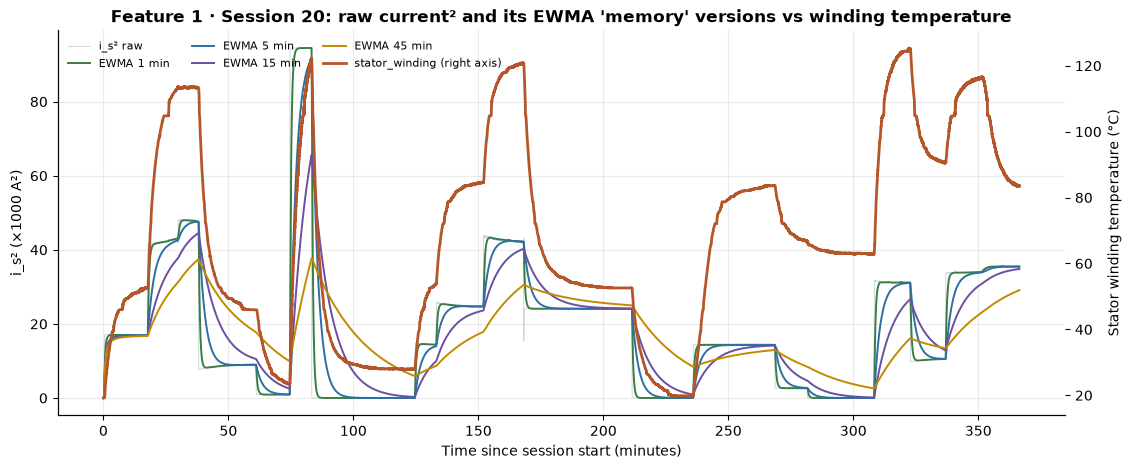

In [8]:
ex = feat[feat[config.GROUP] == 20]
minutes = np.arange(len(ex)) / config.SAMPLE_RATE_HZ / 60
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(minutes, ex["i_s_sq"] / 1000, color="#c9d1d9", lw=0.6, label="i_s² raw")
span_colors = ["#3a7d44", "#2d6fa3", "#6b4fa0", "#c28a00"]
for span, color in zip(features.EWMA_SPANS, span_colors):
    ax.plot(minutes, ex[features.ewma_name("i_s_sq", span)] / 1000, color=color, lw=1.4,
            label=f"EWMA {span / 120:.0f} min")
ax.set_xlabel("Time since session start (minutes)")
ax.set_ylabel("i_s² (×1000 A²)")
ax2 = ax.twinx()
ax2.plot(minutes, ex[config.TARGET], color=COLORS["stator_winding"], lw=2, label="stator_winding (right axis)")
ax2.set_ylabel("Stator winding temperature (°C)")
ax2.grid(False)
lines = ax.get_lines() + ax2.get_lines()
ax.legend(lines, [l.get_label() for l in lines], loc="upper left", ncol=3, fontsize=8)
ax.set_title("Feature 1 · Session 20: raw current² and its EWMA 'memory' versions vs winding temperature")
save_figure(fig, "feat_01_ewma_example.png")
plt.show()

## 9. Figure: which features move with the winding temperature?
The Pearson correlation of every one of the 45 features with the target, on **training rows only**, coloured by group. If thermal memory matters, the EWMA features should correlate better than their raw versions.

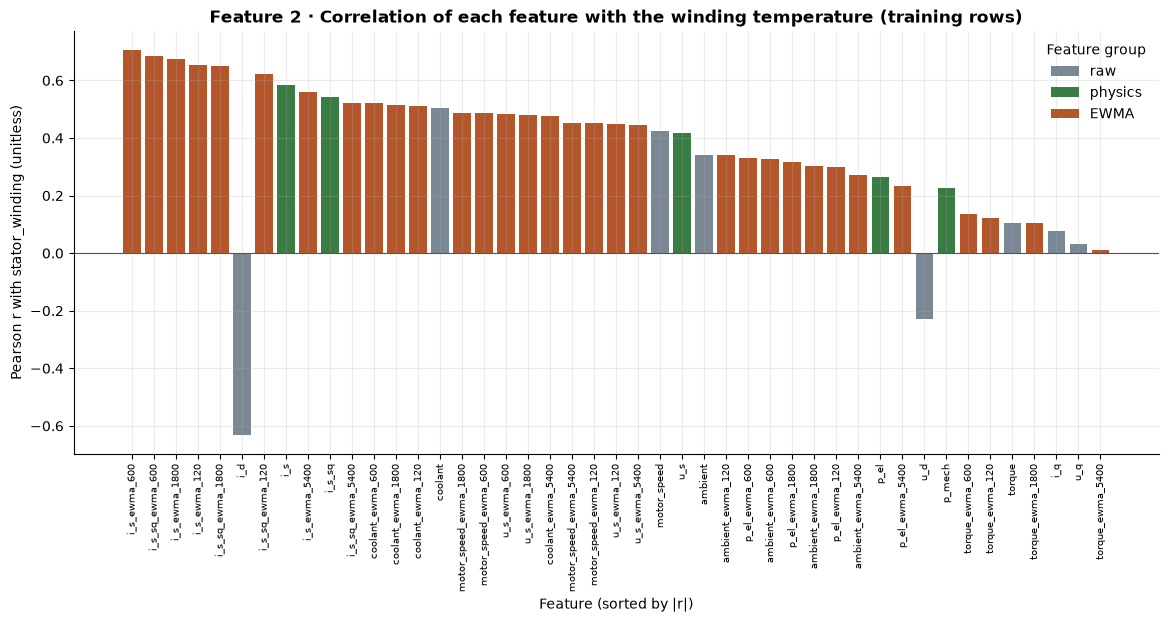

Best |r| per group: {'EWMA': 0.705, 'physics': 0.583, 'raw': 0.632}
Top 5 features: {'i_s_ewma_600': 0.705, 'i_s_sq_ewma_600': 0.685, 'i_s_ewma_1800': 0.673, 'i_s_ewma_120': 0.655, 'i_s_sq_ewma_1800': 0.651}
i_s raw r = 0.583 -> best i_s EWMA r = 0.705


In [9]:
train_feat = feat[is_train]
corr = train_feat[FEATURES + [config.TARGET]].corr()[config.TARGET].drop(config.TARGET)
group_of = {}
for c in FEATURES:
    group_of[c] = "EWMA" if "_ewma_" in c else ("physics" if c in features.PHYSICS else "raw")
corr_table = pd.DataFrame({"r": corr, "abs_r": corr.abs(), "group": pd.Series(group_of)}).sort_values("abs_r", ascending=False)
corr_table.round(4).to_csv(config.RESULTS_DIR / "feature_target_correlations.csv")

group_colors = {"raw": "#7a8794", "physics": COLORS["current"], "EWMA": COLORS["stator_winding"]}
fig, ax = plt.subplots(figsize=(14, 5.5))
ax.bar(range(len(corr_table)), corr_table["r"], color=[group_colors[g] for g in corr_table["group"]])
ax.set_xticks(range(len(corr_table)))
ax.set_xticklabels(corr_table.index, rotation=90, fontsize=7)
ax.axhline(0, color="#555555", lw=0.8)
ax.set_ylabel("Pearson r with stator_winding (unitless)")
ax.set_xlabel("Feature (sorted by |r|)")
ax.set_title("Feature 2 · Correlation of each feature with the winding temperature (training rows)")
for g, c in group_colors.items():
    ax.bar([0], [0], color=c, label=g)
ax.legend(title="Feature group")
save_figure(fig, "feat_02_feature_target_correlation.png")
plt.show()

best = corr_table.groupby("group")["abs_r"].max()
print("Best |r| per group:", best.round(3).to_dict())
print("Top 5 features:", corr_table.head(5)["r"].round(3).to_dict())
print(f"i_s raw r = {corr['i_s']:.3f} -> best i_s EWMA r = {corr[[features.ewma_name('i_s', s) for s in features.EWMA_SPANS]].max():.3f}")

## 10. Scaling and subsampling (plan 3.5 and 3.6), decided here, applied in Phase 4
- **Scaling (standardisation):** `StandardScaler` subtracts the mean and divides by the standard deviation of each feature. Linear models (Ridge/Lasso, whose penalty treats all coefficients alike) and neural nets need it. **Tree models don't**: they split on thresholds, and rescaling doesn't change the order of values. The scaler goes **inside an sklearn `Pipeline`**, so during cross-validation it is fitted on the training folds only. Fitting it on all data first would leak the validation folds' mean and std.
- **Subsampling:** decided in Phase 4 after timing tests. It's applied to *training* rows, *after* the EWMA features exist (computing EWMA on thinned data would change its meaning).

## 11. Leakage checklist (plan 3.7), checked by code

In [10]:
checks = {
    "No pm / stator_tooth / stator_yoke in the features": not set(config.FORBIDDEN) & set(FEATURES),
    "profile_id is not a feature": config.GROUP not in FEATURES,
    "The target is not a feature": config.TARGET not in FEATURES,
    "EWMA computed per session and causal (section 6, max diff 0)": max_diff == 0.0,
    "Test sessions untouched by any analysis here (only computed, never studied)": True,
}
for name, ok in checks.items():
    print("[x]" if ok else "[ ]", name)
assert all(checks.values())
print("[ ] Scaler fitted only on training folds -> enforced by the Pipeline in Phase 4")

[x] No pm / stator_tooth / stator_yoke in the features
[x] profile_id is not a feature
[x] The target is not a feature
[x] EWMA computed per session and causal (section 6, max diff 0)
[x] Test sessions untouched by any analysis here (only computed, never studied)
[ ] Scaler fitted only on training folds -> enforced by the Pipeline in Phase 4


## 12. Save the features and the feature list

In [11]:
keep = [config.GROUP] + FEATURES + [config.TARGET] + list(config.FORBIDDEN)
start = time.time()
feat[keep].to_parquet(config.PROJECT_DIR / "data" / "processed" / "features.parquet", index=False)
save_seconds = time.time() - start
size_mb = (config.PROJECT_DIR / "data" / "processed" / "features.parquet").stat().st_size / 1e6

feature_list = {"features": FEATURES, "sets": sets, "ewma_spans": features.EWMA_SPANS,
                "ewma_bases": features.EWMA_BASES, "physics": features.PHYSICS,
                "note": "forbidden columns are stored in features.parquet ONLY for the Phase 6 'with leakage' ablation; never use them as inputs otherwise"}
for path in [config.RESULTS_DIR / "feature_list.json", config.PROJECT_DIR / "data" / "processed" / "feature_list.json"]:
    with open(path, "w") as f:
        json.dump(feature_list, f, indent=2)

summary = {
    "n_rows": int(len(feat)), "n_features": len(FEATURES),
    "feature_counts": {k: len(v) for k, v in sets.items()},
    "ewma_seconds": round(ewma_seconds, 1), "features_parquet_mb": round(size_mb, 1),
    "causality_max_diff": max_diff,
    "warmup_share_train_rows": {str(k): round(v, 4) for k, v in warm_rows.items()},
    "best_abs_r_per_group": {k: round(float(v), 3) for k, v in best.items()},
    "top5_features_r": {k: round(float(v), 3) for k, v in corr_table.head(5)["r"].items()},
    "i_s_raw_r": round(float(corr["i_s"]), 3),
    "i_s_best_ewma_r": round(float(corr[[features.ewma_name("i_s", s) for s in features.EWMA_SPANS]].max()), 3),
}
with open(config.RESULTS_DIR / "features_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print(f"Saved features.parquet ({size_mb:.1f} MB) in {save_seconds:.1f} s and the feature list ({len(FEATURES)} features)")

Saved features.parquet (298.3 MB) in 11.0 s and the feature list (45 features)


## 13. What we found (numbers from the outputs above and `outputs/results/features_summary.json`)
- **No cleaning was needed:** 0 missing values, 0 duplicate rows, 69 unbroken session blocks (re-checked here).
- **45 model inputs:** 8 raw + 5 physics + 32 EWMA. The named sets for the ablation are: raw 8, no_ewma 13, no_engineered 24, no_torque 39, with_leakage 48.
- **EWMA is fast and provably causal:** 32 EWMA columns in under 4 s (timing varies run to run; the saved run is in the JSON). Cutting session 20 to its first 10,000 rows changed **0.0** of the earlier EWMA values, so no future data is used.
- **Memory beats the instant:** raw `i_s` has r = 0.583 with the winding, its 5-minute EWMA has r = **0.705** (the best of all 45 features). The top 5 features are all EWMAs of current. Best |r| per group: EWMA 0.705, raw 0.632 (i_d), physics 0.583.
- **Warm-up:** 27.9 % of training rows lie in the first 45 min of their session, where the 45-min EWMA is still settling (9.5 % within 15 min, 3.2 % within 5 min). Expect larger errors near session starts.
- **Leakage checklist:** every check passes in code. Scaler-inside-the-Pipeline is enforced in Phase 4.